# Проект «Макромодель Долгопрудного»

В заключительном проекте курса вам нужно будет построить макромодель транспортной системы «континентального» Долгопрудного. Это чудесная часть города, которую с севера и запада ограничивает канал имени Москвы, с юга — промзона, а с востока — железная дорога. Точная граница лежит в файле `area.csv`.

Вам престоит город на транспортные районы, собрать улично-дорожную сеть, оценить, сколько поездок на личном транспорте совершается между районами, и распределить эти поездки по сети. После этого модель нужно будет откалибровать.

Проверять модели мы будем на данных об интенсивности движения на дорогах Долгопрудного. Часть этих замеров доступна ниже, а по остальным мы оценим точность построенной модели.

## Команды

Проект делается в командах по 2-4 человека. Состав команды нужно прислать до 25 октября включительно в личные сообщения старшему ассистенту [Алексею Фёдорову](https://time.cu.ru/tsentralnyy-universitet/messages/@al.a.fedorov).

## Что нужно сделать

Моделировать нужно утро буднего дня с 7:00 до 9:00 по получасам: 7:00-7:30, 7:30-8:00, 8:00-8:30 и 8:30-9:00.

1. **Районирование.** Разбейте город на транспортные районы. Подумайте, как можно справиться с выездом и въездом в город: благо, основных таких мест всего три.
2. **Сеть.** Получите граф дорог из OpenStreetMap. Подумайте, какие параметры должны быть у рёбер и как связать граф с районами.
3. **Спрос.** Постройте матрицу корреспонденций.
4. **Распределение.** Найдите пользовательское равновесие.
5. **Калибровка.** Подберите параметры модели так, чтобы полученные потоки бились с опубликованными данными.
6. **Потоки в точках проверки.** Посчитайте потоки своей модели во всех точках из файла `points.csv` для каждого получаса и заполните файл с названием `flows.csv` по шаблону `flows_template.csv`.

## Инструментарий

Для построения модели можно использовать любые инструменты, в том числе свой код на Python, готовые библиотеки или программы для моделирования. Главное, чтобы решение было вашим, и чтобы вы разбирались во всех применённых методах (vibemodeling запрещён!), а ассистенты могли запустить ваше решение с нуля и получить `flows.csv` в указанном формате.

## Какие данные можно использовать

Одним из основных источников данных для вас может стать OpenStreetMap. В нём можно получить данные как по дорожному графу, так и по зданиям и капитальным объектам. Скачать данные можно любым удобным способом, например, через библиотеку [osmnx](https://osmnx.readthedocs.io/).

Для внешних районов пригодится население соседних городов, районов Москвы и частей Долгопрудного за каналом и железной дорогой. Его можно взять, например, из [слоя муниципальных образований Центра геоданных ВШЭ](https://geoportal.hse.ru/portal/apps/sites/#/geodata/datasets/12e78b9c3bf04feea944f9d53eb3d079/about) или из [муниципальной статистики Росстата](https://rosstat.gov.ru/munstat). Больше открытых источников собрано на слайдах восьмой недели.

Ещё один полезный источник — [датасет Циана с объявлениями о недвижимости](https://huggingface.co/datasets/cianml/ru-real-estate-geo-temporal-clusters) за 2024-2025 годы. Объявления там собраны в клетки площадью примерно четверть квадратного километра, и у каждой клетки есть число объявлений, цены, год постройки и этажность домов. Датасет собран по Москве, поэтому «континентальный» Долгопрудный в него не попал, зато соседние районы Москвы покрыты хорошо. Подробнее о датасете написано в [статье его авторов](https://dl.acm.org/doi/10.1145/3805712.3808616), одна из них — [Ирина Подлипнова](https://time.cu.ru/tsentralnyy-universitet/messages/@i.podlipnova), преподаватель нашего курса.

Можно использовать и любые другие открытые данные, однако полный их список нужно указать в презентации на защите.

## Замеры для калибровки и проверки

Файлы `area.csv`, `points.csv`, `calibration.csv` и `flows_template.csv` прикреплены к заданию в LMS, а на картинке ниже нарисованы граница области и все места из `points.csv`. В `points.csv` перечислены все места, где нужно посчитать потоки: название, координаты и направление движения. Все они лежат внутри области. В каждом месте рассматриваются оба направления, у каждого направления есть свой номер.

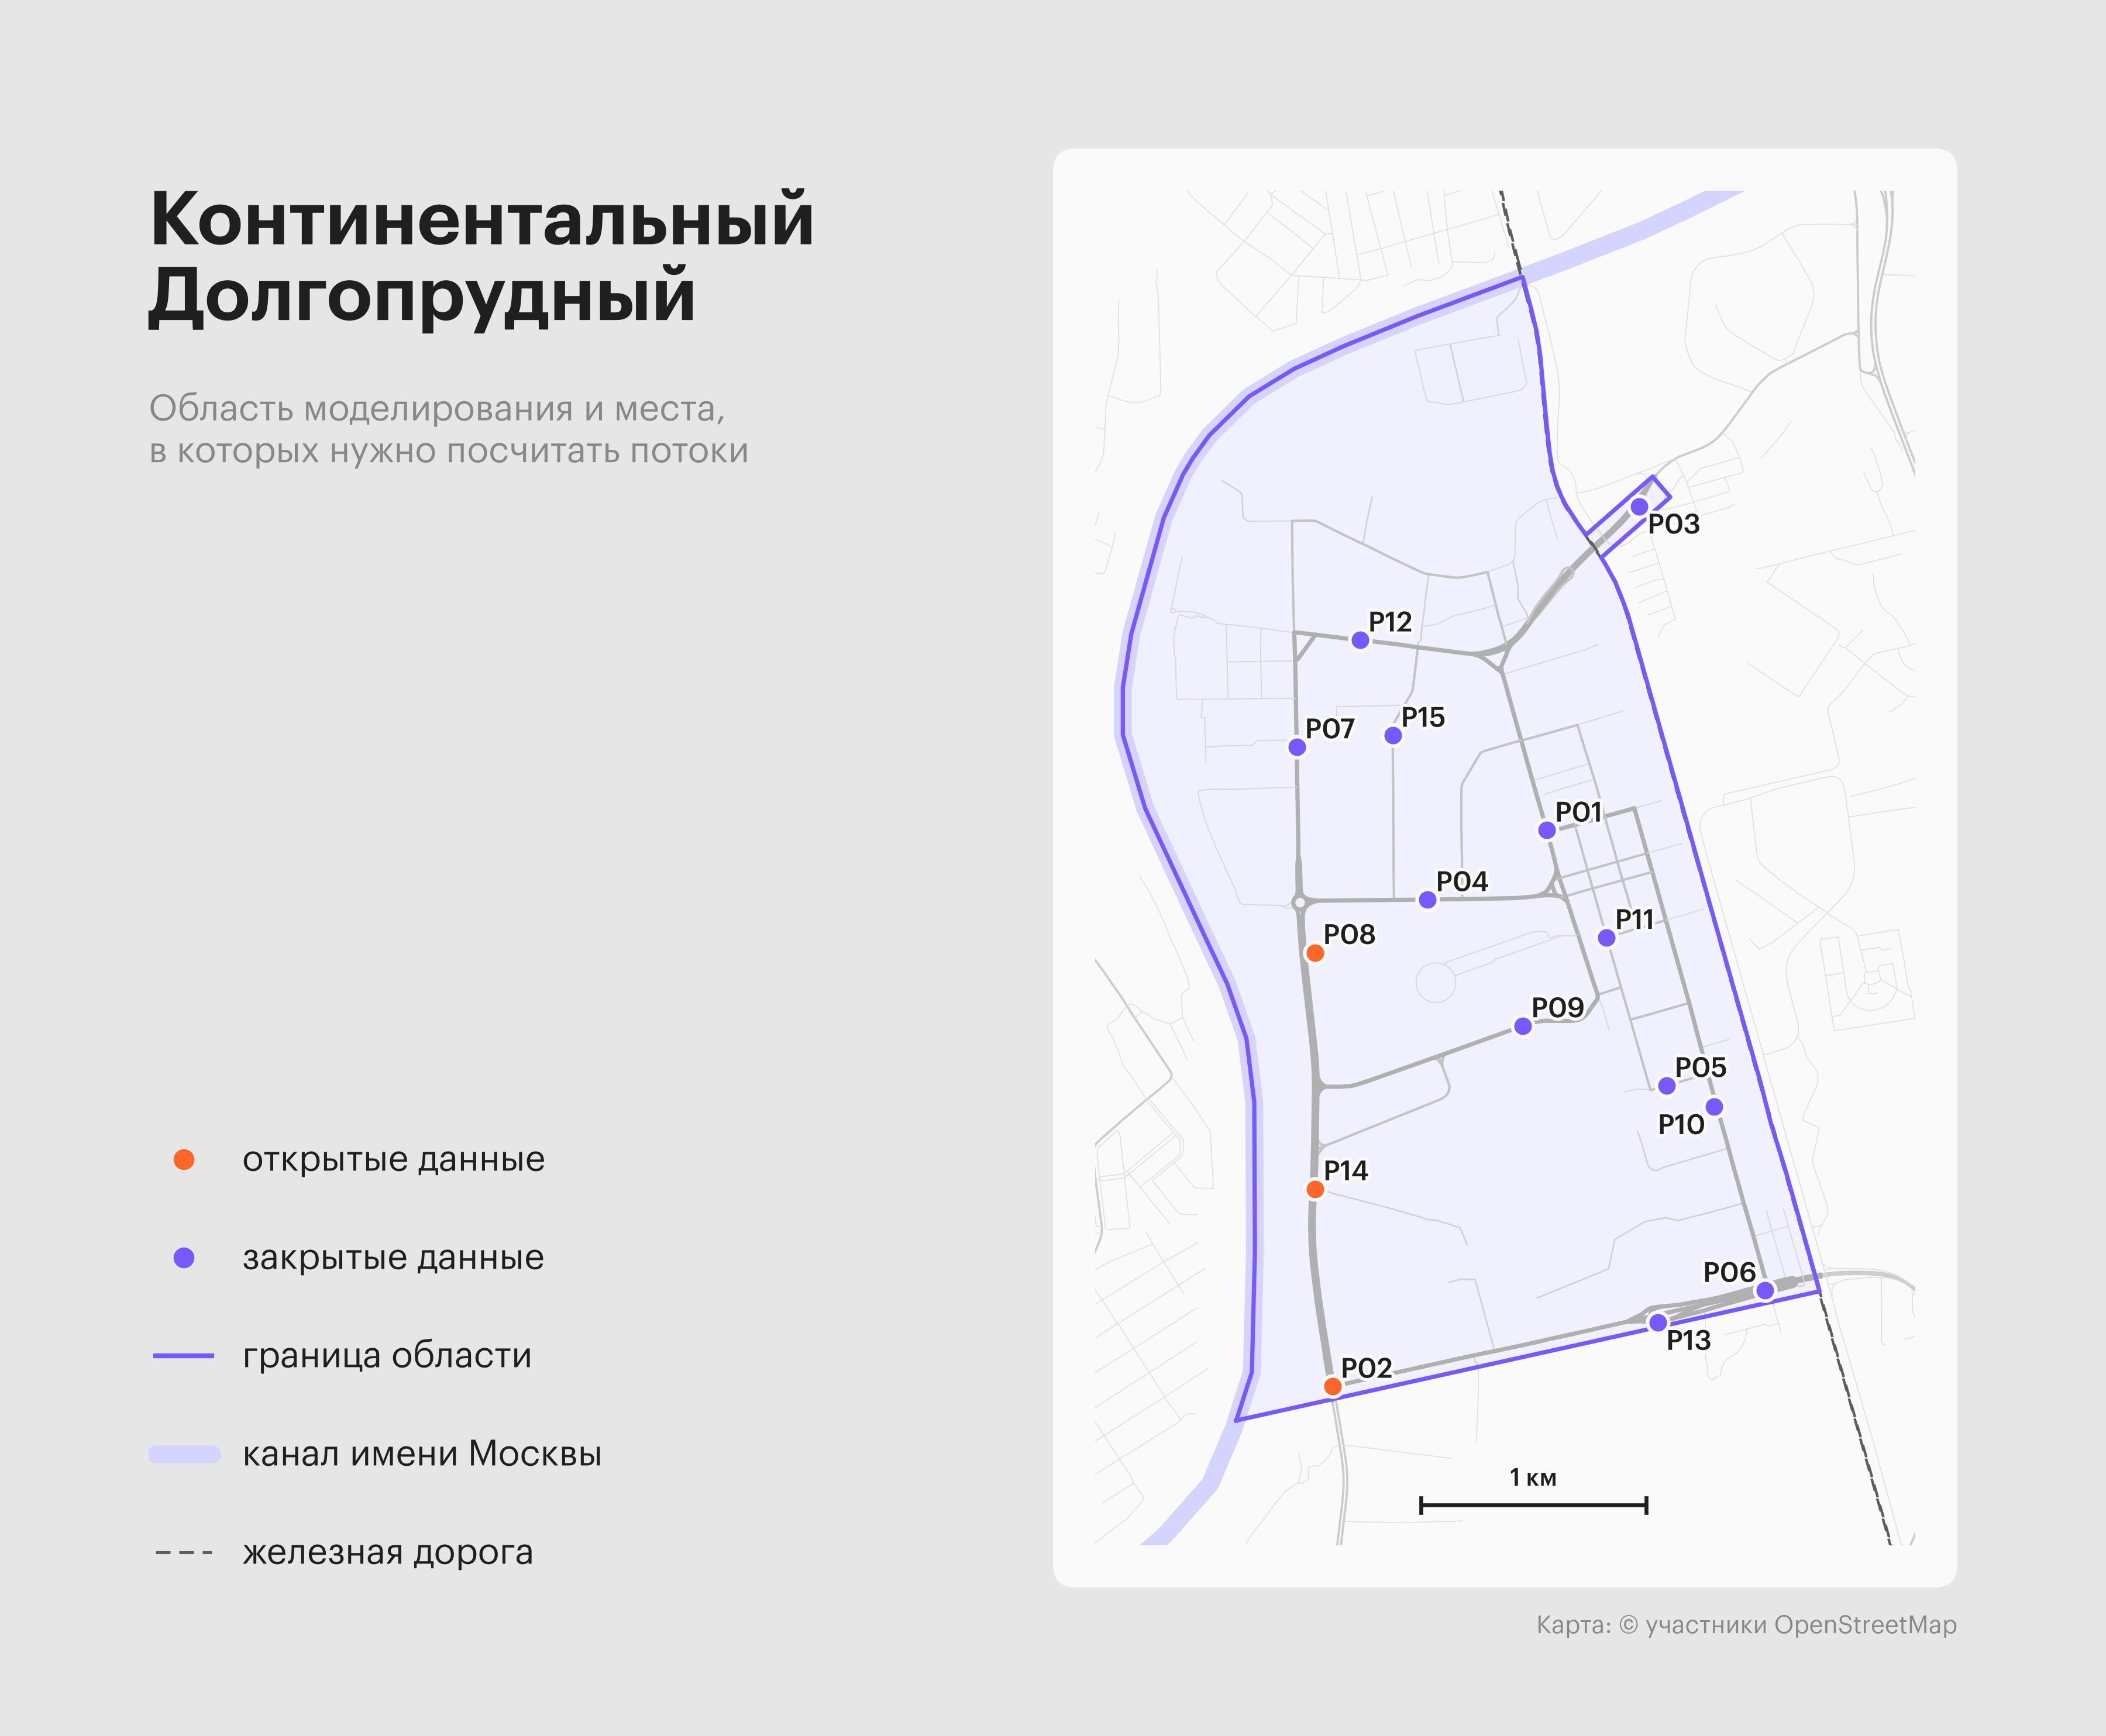

В **открытых данных** (файл `calibration.csv`) лежит информация о камерах на Лихачёвском проспекте, одном из главных въездов в город со стороны Москвы. Для каждой камеры дан поток в автомобилях в час за два часа, с 7 до 8 и с 8 до 9 утра, это медиана по замерам в будни. Камеры считают поток только по часам, поэтому сравнивать с ними нужно среднее двух ваших получасовых интенсивностей. Это то же самое, что сложить число машин за оба получаса. В **закрытых данных** лежат потоки по другим точкам города за те же утренние часы, но уже с шагом в полчаса.

## Метрика качества

Для каждого направления и каждого получаса считается статистика GEH, она названа по инициалам её автора [Джеффри Э. Хаверса](https://en.wikipedia.org/wiki/GEH_statistic) (Geoffrey E. Havers):

$$
GEH = \sqrt{\frac{2(M - C)^2}{M + C}},
$$

где $M$ — поток вашей модели, а $C$ — истинный замер, оба измеряются в автомобилях в час. Пороги GEH придуманы для часовых потоков, поэтому каждый получас сравнивается в пересчёте на час: число машин за получас умножается на два. Например, если за 30 минут проехало 400 машин, в сравнение идёт 800 автомобилей в час.

*Пояснение:* это классическая метрика для сравнения потоков в модели с реальными интенсивностями. А почему не MAPE, MAE или MSE? Дело в том, что простая относительная ошибка оказывается слишком строгой к маленьким потокам, а абсолютная — к большим. GEH устроен так, что справедливо оценивает и те, и другие. Значение этой метрики меньше 5 считается хорошим совпадением, меньше 10 — приемлемым. Например, при потоке около 800 автомобилей в час GEH меньше 5 получится, если модель ошиблась не больше чем примерно на 18% (144 автомобиля в час), а при потоке в 300 автомобилей — не больше чем примерно на 31% (93 автомобиля в час).

Итоговая метрика — это средний GEH по всем закрытым точкам, направлениям и интервалам в 30 минут.

## Предзащита

На девятой неделе (2-8 ноября) будет проведена предзащита, за участие в которой можно получить до 3 бонусных баллов. На предзащите можно продемонстрировать промежуточные результаты по проекту, получить от членов жюри обратную связь и задать им вопросы.

Допускается пропуск предзащиты, однако участие в ней крайне желательно. На ней в том числе можно один раз узнать свой средний GEH по закрытым данным. Для этого нужно будет прислать `flows.csv` по шаблону.

## Загрузка в LMS перед защитой

Файлы загружает один участник от команды не позже чем за два дня до защиты.

1. **flows.csv** по шаблону `flows_template.csv`: в первом столбце номер направления из `points.csv`, дальше четыре столбца по одному на каждые 30 минут. В каждой ячейке нужно указать поток вашей модели в пересчёте на автомобили в час (в интенсивностях учтите все типы транспорта). Заполнить нужно все строки и все столбцы.
2. **Код.** Ноутбук или архив. Запуск всех ячеек с нуля должен воспроизводить полученный `flows.csv`.

## Защита

Защита пройдёт 19 декабря, на пятнадцатой неделе. На ней нужно продемонстрировать презентацию о проекте (на последнем слайде укажите вклад каждого участника в процентах, в сумме они должны давать 100%) и быть готовыми ответить на вопросы. На доклад у команды будет 7 минут и ещё 3 минуты на вопросы.

## Как оценивается проект

Команда получает оценку от 0 до 10, а дальше она корректируется по вкладу каждого участника согласно [формуле оценки курса](https://time.cu.ru/tsentralnyy-universitet/pl/18iasfgzrbszs554i64p6p7g3n). Проект весит 40% итоговой оценки, а индивидуальная оценка за проект меньше 3,5 балла является блокером.

Неверно думать, что оценка будет выставляться исключительно по значению GEH. Оцениваются в совокупности построение, точность модели и защита. Чтобы сдать проект, модель должна пройти все шаги построения, а `flows.csv` должен быть заполнен. Сильную работу отличает то, что выбор исходных данных, районирования и значений спроса обоснованы, описана калибровка, а команда понимает, где модель ошибается и почему. Точность на закрытых замерах тоже важна, но замерам почти три года, и хорошая модель может разойтись с ними по вполне понятным причинам. Куда важнее то, сможете ли вы эти причины объяснить.

ИИ-помощниками, как и сказано в силлабусе, можно пользоваться для генерации идей и рутинных задач. Но во всех методах, которые вы используете в модели, нужно разбираться на все 100%. На защите мы прежде всего будем спрашивать именно про них.

## Дополнительное задание

Доп. задание не обязательно, однако участники пяти команд, которые лучше всего справятся с ним, получат бонусные баллы и / или повышение оценки за аудиторную активность по соответствующим темам. Можно выбрать один из вариантов:

1. **The road not taken.** В 2023 году в МФТИ изучали: что будет с городом, если закрыть Институтский переулок для транзита? Использующиеся в проекте замеры собирали как раз для того исследования. Повторите эксперимент на своей модели. Как перераспределятся потоки?
2. **Лучшее — друг хорошего.** Для уточнения модели вам доступны следующие опции: добавить общественный транспорт или замоделировать вечерний час пик. Доработайте модель и проанализируйте полученные результаты. О найденных инсайтах (или их отсутствии) можно рассказать на защите.

## Сроки

Составы команд нужно прислать до 25 октября. Предзащита по желанию пройдёт на девятой неделе, 2-8 ноября. Файлы нужно загрузить в LMS не позже чем за два дня до защиты, а сама защита пройдёт 19 декабря.

Если что-то непонятно — смело пишите в канал курса или в личку лиду / старшему ассистенту курса. Будем рады помочь, удачи! :)

> *Тает в дымке город Химки*
>
> *До свиданья, мне пора*
>
> *В Долгопрудный, где так чудны*
>
> *Подмосковные вечера...*